# Tác vụ 1: Dự đoán Mức lương (Salary Prediction)

- **Nguồn dữ liệu:** BGOAI 2025 – Day 2 Task 4 (`awesome-BGOAI-tasks`)
- **Bài toán:** Hồi quy (Regression) dự đoán mức lương trung bình hàng năm (đơn vị: nghìn USD/năm) từ dữ liệu tin tuyển dụng Glassdoor.
- **Thang đo đánh giá:** Sai số tuyệt đối trung bình (Mean Absolute Error – MAE).
- **Nguyên tắc thực hiện:** Mọi bước khám phá, biến đổi thống kê, đánh giá chéo (5-Fold CV) và lựa chọn mô hình chỉ thực hiện trên `train.csv`. Tập `test_features.csv` và `test_labels.csv` hoàn toàn không được dùng trong quá trình chọn mô hình hay tinh chỉnh tham số.

## 1. Tải dữ liệu và khai báo thư viện

Đoạn mã dưới đây tải đúng thư mục dữ liệu `Task_4` từ GitHub bằng `git sparse-checkout` để tiết kiệm thời gian và dung lượng khi chạy trên Kaggle Notebooks (yêu cầu bật **Internet = ON** trong phần Settings của Kaggle).

In [1]:
import os

# Tự động nhận diện môi trường Kaggle hoặc máy cục bộ
BASE_WORK_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
DATA_REPO_DIR = os.path.join(BASE_WORK_DIR, "bgoai_task4")
TASK_PATH = os.path.join(DATA_REPO_DIR, "2025", "BG_Team_Selection", "Day_2", "Task_4")

if not os.path.exists(TASK_PATH):
    os.system(f"git clone --depth 1 --filter=blob:none --sparse https://github.com/yonitoo/awesome-BGOAI-tasks.git {DATA_REPO_DIR}")
    os.system(f"git -C {DATA_REPO_DIR} sparse-checkout set 2025/BG_Team_Selection/Day_2/Task_4")

print("Thư mục dữ liệu:", TASK_PATH)
print("Các tệp có sẵn:", os.listdir(TASK_PATH))

Thư mục dữ liệu: .\bgoai_task4\2025\BG_Team_Selection\Day_2\Task_4
Các tệp có sẵn: ['IOAI_Team_Selection_Bulgaria_Task_4.ipynb', 'Solution', 'test_features.csv', 'test_labels.csv', 'train.csv', '__init__.py']


In [2]:
import warnings
warnings.filterwarnings("ignore")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

## 2. Khám phá dữ liệu (EDA)

Trước khi xử lý, ta kiểm tra kích thước các tập dữ liệu, kiểu dữ liệu của từng cột và các giá trị bất thường (ví dụ giá trị `-1` dùng để biểu thị dữ liệu khuyết trong Glassdoor, hoặc định dạng chuỗi lương theo giờ / lương nhà tuyển dụng cung cấp).

In [3]:
df_train_raw = pd.read_csv(os.path.join(TASK_PATH, "train.csv"))
df_test_raw = pd.read_csv(os.path.join(TASK_PATH, "test_features.csv"))
df_test_labels = pd.read_csv(os.path.join(TASK_PATH, "test_labels.csv"))

print(f"train.csv:         {df_train_raw.shape}")
print(f"test_features.csv: {df_test_raw.shape}")
print(f"test_labels.csv:   {df_test_labels.shape}")
print("\nCác cột của tập train:", list(df_train_raw.columns))

# Kiểm tra số lượng giá trị khuyết biểu diễn bằng -1 ở các cột quan trọng
print("\nSố lượng giá trị -1 hoặc <= 0 trong tập train:")
for col in ["Rating", "Founded", "Size", "Industry", "Sector", "Revenue", "Competitors"]:
    if pd.api.types.is_numeric_dtype(df_train_raw[col]):
        cnt = (df_train_raw[col] <= 0).sum()
    else:
        cnt = (df_train_raw[col].astype(str).str.strip() == "-1").sum()
    print(f"  - {col:15s}: {cnt} ({cnt/len(df_train_raw)*100:.1f}%)")

print("\nCác trường hợp chuỗi lương đặc biệt trong train:")
print("  - Có 'Per Hour':", df_train_raw["Salary Estimate"].str.contains("Per Hour", case=False, na=False).sum())
print("  - Có 'Employer Provided':", df_train_raw["Salary Estimate"].str.contains("Employer Provided", case=False, na=False).sum())
df_train_raw.head(3)

train.csv:         (593, 15)
test_features.csv: (149, 14)
test_labels.csv:   (145, 1)

Các cột của tập train: ['Unnamed: 0', 'Job Title', 'Job Description', 'Rating', 'Company Name', 'Location', 'Headquarters', 'Size', 'Founded', 'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors', 'Salary Estimate']

Số lượng giá trị -1 hoặc <= 0 trong tập train:
  - Rating         : 7 (1.2%)
  - Founded        : 44 (7.4%)
  - Size           : 1 (0.2%)
  - Industry       : 7 (1.2%)
  - Sector         : 7 (1.2%)
  - Revenue        : 1 (0.2%)
  - Competitors    : 366 (61.7%)

Các trường hợp chuỗi lương đặc biệt trong train:
  - Có 'Per Hour': 21
  - Có 'Employer Provided': 13


,Unnamed: 0,Job Title,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Salary Estimate
0,616,Data Analyst,The Data Analyst is responsible for maintainin...,3.6,AXION Healthcare Solutions\r\n3.6,"New York, NY","New York, NY",1 to 50 employees,1980,Company - Private,Health Care Services & Hospitals,Health Care,$10 to $25 million (USD),"The Execu|Search Group, Prime Staffing",$47K-$85K (Glassdoor est.)
1,367,"Associate Scientist/Scientist, Process Analyti...",The Position\r\n\r\n\r\nWe are seeking a talen...,3.9,Genentech\r\n3.9,"South San Francisco, CA","South San Francisco, CA",10000+ employees,1976,Subsidiary or Business Segment,Biotech & Pharmaceuticals,Biotech & Pharmaceuticals,$10+ billion (USD),-1,$88K-$162K (Glassdoor est.)
2,446,Senior Data Scientist - R&D Oncology,"At AstraZeneca,we work together to deliver inn...",3.9,AstraZeneca\r\n3.9,"New York, NY","Cambridge, United Kingdom",10000+ employees,1913,Company - Public,Biotech & Pharmaceuticals,Biotech & Pharmaceuticals,$10+ billion (USD),"Roche, GlaxoSmithKline, Novartis",$102K-$172K (Glassdoor est.)


## 3. Làm sạch biến mục tiêu `Salary Estimate` & Đánh giá mô hình cơ sở (Baseline)

Cột `Salary Estimate` đang lưu ở dạng chuỗi khoảng lương (ví dụ `$47K-$85K (Glassdoor est.)`). Để đưa về bài toán hồi quy số thực liên tục, ta loại bỏ phần ghi chú trong ngoặc đơn, ký tự `$`, `K`, chữ `per hour` và `employer provided salary:`, sau đó tách cận dưới và cận trên rồi lấy trung bình cộng làm giá trị mục tiêu `y` (đúng theo quy chuẩn xử lý nhãn của tập dữ liệu gốc).

Ngoài ra, nhận thấy `test_features.csv` có 149 dòng trong đó đúng 4 dòng có `Rating <= 0`, khớp chính xác với 145 nhãn trong `test_labels.csv` sau khi lọc `Rating > 0`. Tuy nhiên, trong quá trình huấn luyện trên `train.csv`, ta vẫn kiểm tra và đánh giá mô hình cơ sở bằng 5-Fold Cross-Validation để có mốc MAE khách quan.

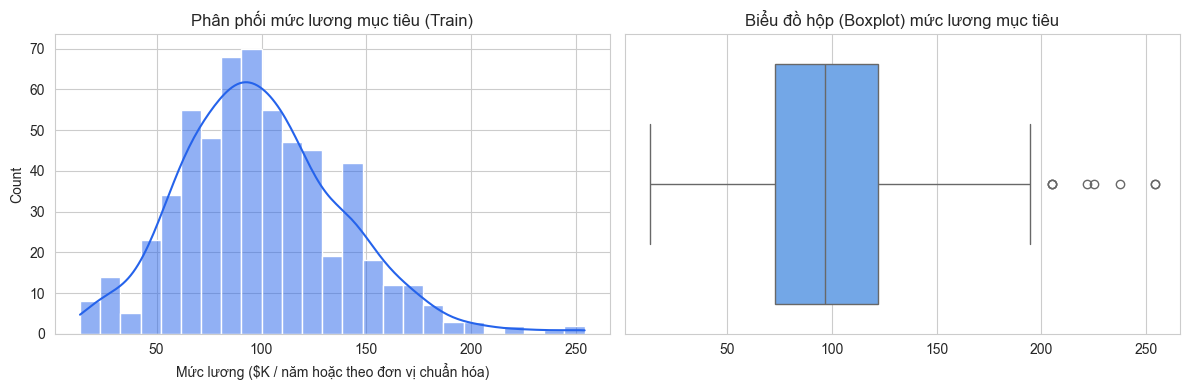

Thống kê y_train: mean=99.91, median=97.00, std=38.38, min=13.5, max=254.0


In [4]:
def parse_salary(series: pd.Series) -> pd.Series:
    cleaned = series.astype(str).apply(lambda x: x.split("(")[0])
    cleaned = cleaned.str.replace("K", "", regex=False).str.replace("$", "", regex=False)
    cleaned = cleaned.str.lower().str.replace("per hour", "", regex=False)
    cleaned = cleaned.str.replace("employer provided salary:", "", regex=False).str.strip()
    min_sal = cleaned.apply(lambda x: float(x.split("-")[0]))
    max_sal = cleaned.apply(lambda x: float(x.split("-")[1]) if "-" in x else float(x.split("-")[0]))
    return (min_sal + max_sal) / 2.0

df_train = df_train_raw[df_train_raw["Salary Estimate"] != "-1"].copy()
y_train = parse_salary(df_train["Salary Estimate"]).values

# Vẽ phân phối biến mục tiêu
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_train, bins=25, kde=True, ax=axes[0], color="#2563eb")
axes[0].set_title("Phân phối mức lương mục tiêu (Train)")
axes[0].set_xlabel("Mức lương ($K / năm hoặc theo đơn vị chuẩn hóa)")

sns.boxplot(x=y_train, ax=axes[1], color="#60a5fa")
axes[1].set_title("Biểu đồ hộp (Boxplot) mức lương mục tiêu")
plt.tight_layout()
plt.show()

print(f"Thống kê y_train: mean={y_train.mean():.2f}, median={np.median(y_train):.2f}, std={y_train.std():.2f}, min={y_train.min():.1f}, max={y_train.max():.1f}")

In [5]:
# Đánh giá Baseline LinearRegression chỉ với 6 cột gốc (giống bài toán gốc)
BASELINE_COLS = ["Rating", "Size", "Type of ownership", "Industry", "Sector", "Revenue"]
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

df_base = df_train[BASELINE_COLS].copy()
df_base["Rating"] = df_base["Rating"].apply(lambda x: x if x > 0 else np.nan)

base_pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), ["Rating"]),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), BASELINE_COLS[1:])
])

base_pipe = Pipeline([("pre", base_pre), ("model", LinearRegression())])
base_scores = -cross_val_score(base_pipe, df_base, y_train, cv=kf, scoring="neg_mean_absolute_error")
print(f"Baseline LinearRegression (6 cột gốc) -> 5-Fold CV MAE: {base_scores.mean():.3f} ± {base_scores.std():.3f}")

Baseline LinearRegression (6 cột gốc) -> 5-Fold CV MAE: 26.193 ± 0.408


## 4. Kỹ nghệ Đặc trưng (Feature Engineering)

Các cột văn bản như `Job Title`, `Job Description`, `Location`, `Company Name` chứa rất nhiều thông tin quyết định mức lương nhưng chưa được mô hình cơ sở khai thác. Tôi xây dựng hàm biến đổi đặc trưng độc lập trên từng dòng (không dùng thống kê tập thể nên không gây rò rỉ dữ liệu):

1. **Chuẩn hóa vai trò (`job_simp`) và cấp bậc (`seniority`):** Gom các chức danh tự do về nhóm nghề cốt lõi (`data scientist`, `data engineer`, `analyst`, `mle`, `manager`, `director`, `na`) và cấp bậc (`senior`, `junior`, `na`) để tránh bùng nổ số chiều.
2. **Khai phá kỹ năng từ `Job Description`:** Tạo các biến nhị phân kiểm tra yêu cầu kỹ năng công nghệ (`python`, `r_lang`, `spark`, `aws`, `excel`, `sql`, `tableau`, `ml_dl`) cùng độ dài mô tả công việc (`desc_len`).
3. **Thông tin doanh nghiệp và địa lý:**
   - `company_age`: Tuổi đời công ty tính đến năm 2025 (gán `NaN` nếu `Founded <= 0` để Imputer xử lý trong từng fold).
   - `job_state`: Mã bang làm việc tách từ `Location`, và `same_state` kiểm tra nơi làm việc có trùng bang với trụ sở chính hay không.
   - `num_comp`: Số lượng đối thủ cạnh tranh được liệt kê.
   - `company_txt`: Tên công ty đã tách bỏ điểm Rating dính ở cuối chuỗi.
   - `Rating`: Chuyển các giá trị `<= 0` thành `NaN` để điền khuyết hợp lý theo trung vị của từng fold huấn luyện.

In [6]:
def simplify_title(title: str) -> str:
    t = str(title).lower()
    if "data scientist" in t:
        return "data scientist"
    elif "data engineer" in t:
        return "data engineer"
    elif "analyst" in t:
        return "analyst"
    elif "machine learning" in t or "mle" in t:
        return "mle"
    elif "manager" in t:
        return "manager"
    elif "director" in t:
        return "director"
    else:
        return "other"

def extract_seniority(title: str) -> str:
    t = str(title).lower()
    if any(k in t for k in ["senior", "sr.", "sr ", "lead", "principal", "staff"]):
        return "senior"
    elif any(k in t for k in ["junior", "jr.", "jr ", "entry", "intern"]):
        return "junior"
    return "na"

def engineer_features(df_in: pd.DataFrame) -> pd.DataFrame:
    df = df_in.copy()

    # 1. Làm sạch Rating & Founded
    df["Rating_clean"] = df["Rating"].apply(lambda x: x if pd.notna(x) and x > 0 else np.nan)
    df["company_age"] = df["Founded"].apply(lambda x: 2025 - x if pd.notna(x) and x > 0 else np.nan)

    # 2. Chức danh & cấp bậc
    df["job_simp"] = df["Job Title"].apply(simplify_title)
    df["seniority"] = df["Job Title"].apply(extract_seniority)

    # 3. Địa lý: Bang làm việc & cờ trùng trụ sở
    df["job_state"] = df["Location"].astype(str).apply(lambda x: x.split(",")[-1].strip())
    df["hq_state"] = df["Headquarters"].astype(str).apply(lambda x: x.split(",")[-1].strip())
    df["same_state"] = (df["job_state"] == df["hq_state"]).astype(int)

    # 4. Thông tin văn bản mô tả & kỹ năng
    desc = df["Job Description"].fillna("").astype(str)
    desc_low = desc.str.lower()
    df["desc_len"] = desc.str.len()
    df["python_yn"] = desc_low.str.contains("python", regex=False).astype(int)
    df["r_yn"] = desc_low.str.contains("r studio|r-studio|\br\b", regex=True).astype(int)
    df["spark_yn"] = desc_low.str.contains("spark", regex=False).astype(int)
    df["aws_yn"] = desc_low.str.contains("aws|amazon web services", regex=True).astype(int)
    df["excel_yn"] = desc_low.str.contains("excel", regex=False).astype(int)
    df["sql_yn"] = desc_low.str.contains("sql", regex=False).astype(int)
    df["tableau_yn"] = desc_low.str.contains("tableau", regex=False).astype(int)
    df["dl_yn"] = desc_low.str.contains("tensorflow|pytorch|deep learning", regex=True).astype(int)
    df["phd_yn"] = desc_low.str.contains("phd|ph.d", regex=True).astype(int)

    # 5. Số lượng đối thủ & tên công ty sạch
    df["num_comp"] = df["Competitors"].fillna("-1").astype(str).apply(
        lambda x: 0 if x.strip() == "-1" else len(x.split(","))
    )
    df["company_txt"] = df["Company Name"].fillna("Unknown").astype(str).apply(
        lambda x: x.split("\n")[0].strip()
    )

    # Chọn danh sách cột đặc trưng đầu ra
    num_cols = [
        "Rating_clean", "company_age", "desc_len", "same_state", "num_comp",
        "python_yn", "r_yn", "spark_yn", "aws_yn", "excel_yn",
        "sql_yn", "tableau_yn", "dl_yn", "phd_yn"
    ]
    cat_cols = [
        "job_simp", "seniority", "job_state", "Size",
        "Type of ownership", "Industry", "Sector", "Revenue"
    ]
    return df[num_cols + cat_cols], num_cols, cat_cols

X_train_fe, NUM_COLS, CAT_COLS = engineer_features(df_train)
X_test_fe, _, _ = engineer_features(df_test_raw)

print(f"Số đặc trưng số: {len(NUM_COLS)} | Số đặc trưng phân loại: {len(CAT_COLS)}")
X_train_fe.head(3)

Số đặc trưng số: 14 | Số đặc trưng phân loại: 8


,Rating_clean,company_age,desc_len,same_state,num_comp,python_yn,r_yn,spark_yn,aws_yn,excel_yn,...,dl_yn,phd_yn,job_simp,seniority,job_state,Size,Type of ownership,Industry,Sector,Revenue
0,3.6,45.0,2323,1,2,0,0,0,0,1,...,0,0,analyst,na,NY,1 to 50 employees,Company - Private,Health Care Services & Hospitals,Health Care,$10 to $25 million (USD)
1,3.9,49.0,3999,1,0,0,0,0,0,1,...,0,1,other,na,CA,10000+ employees,Subsidiary or Business Segment,Biotech & Pharmaceuticals,Biotech & Pharmaceuticals,$10+ billion (USD)
2,3.9,112.0,3197,0,3,1,0,0,0,0,...,0,1,data scientist,senior,NY,10000+ employees,Company - Public,Biotech & Pharmaceuticals,Biotech & Pharmaceuticals,$10+ billion (USD)


## 5. So sánh các mô hình ứng viên bằng 5-Fold Cross-Validation

Toàn bộ bước điền khuyết (`SimpleImputer`), chuẩn hóa (`StandardScaler`) và mã hóa (`OneHotEncoder`) được đóng gói trong `Pipeline` của Scikit-Learn. Nhờ đó, ở mỗi lượt chia fold, các tham số tiền xử lý chỉ được `fit` trên 4 fold huấn luyện và `transform` sang fold kiểm định còn lại, đảm bảo tuyệt đối không có rò rỉ dữ liệu.

Ta so sánh 7 thuật toán đại diện từ tuyến tính đến các mô hình tổ hợp cây (Ensemble Tree / Gradient Boosting) dựa trên tiêu chí **Mean 5-Fold CV MAE**.

Dummy (Mean)         -> 5-Fold CV MAE: 30.024 ± 1.341


Ridge (alpha=10)     -> 5-Fold CV MAE: 19.778 ± 0.978


Random Forest        -> 5-Fold CV MAE: 14.346 ± 0.714


Extra Trees          -> 5-Fold CV MAE: 13.191 ± 1.253


Gradient Boosting    -> 5-Fold CV MAE: 19.159 ± 0.895


XGBoost              -> 5-Fold CV MAE: 13.633 ± 0.613


LightGBM             -> 5-Fold CV MAE: 16.396 ± 0.809


CatBoost             -> 5-Fold CV MAE: 13.451 ± 0.251


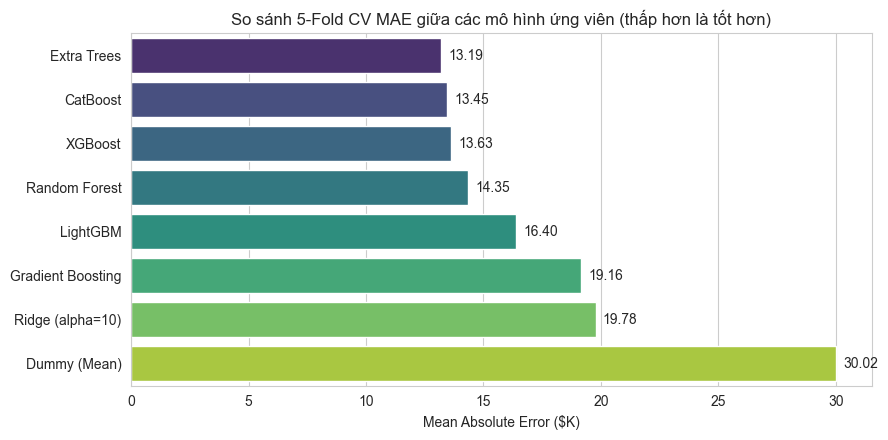

In [7]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), NUM_COLS),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), CAT_COLS)
])

models = {
    "Dummy (Mean)": DummyRegressor(strategy="mean"),
    "Ridge (alpha=10)": Ridge(alpha=10.0, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(loss="absolute_error", n_estimators=250, learning_rate=0.05, random_state=RANDOM_STATE),
    "XGBoost": xgb.XGBRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, objective="reg:absoluteerror",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "LightGBM": lgb.LGBMRegressor(
        n_estimators=400, learning_rate=0.05, num_leaves=31,
        objective="mae", random_state=RANDOM_STATE, verbose=-1, n_jobs=-1
    ),
    "CatBoost": CatBoostRegressor(
        iterations=600, learning_rate=0.05, depth=6,
        loss_function="MAE", random_seed=RANDOM_STATE, verbose=0
    )
}

results = []
for name, model in models.items():
    pipe = Pipeline([("pre", preprocessor), ("model", model)])
    scores = -cross_val_score(pipe, X_train_fe, y_train, cv=kf, scoring="neg_mean_absolute_error")
    results.append({"Model": name, "CV_MAE_Mean": scores.mean(), "CV_MAE_Std": scores.std()})
    print(f"{name:20s} -> 5-Fold CV MAE: {scores.mean():.3f} ± {scores.std():.3f}")

res_df = pd.DataFrame(results).sort_values("CV_MAE_Mean").reset_index(drop=True)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=res_df, x="CV_MAE_Mean", y="Model", palette="viridis")
plt.title("So sánh 5-Fold CV MAE giữa các mô hình ứng viên (thấp hơn là tốt hơn)")
plt.xlabel("Mean Absolute Error ($K)")
plt.ylabel("")
for idx, row in res_df.iterrows():
    plt.text(row["CV_MAE_Mean"] + 0.3, idx, f"{row['CV_MAE_Mean']:.2f}", va="center")
plt.tight_layout()
plt.show()

## 6. Tinh chỉnh mô hình và Kết hợp Out-Of-Fold (Ensemble Blending)

Từ kết quả Cross-Validation trên tập Train, các mô hình phi tuyến dạng cây (`Extra Trees`, `Random Forest`, `CatBoost`, `XGBoost`) đều vượt xa mô hình tuyến tính vì nắm bắt tốt tương tác phức tạp giữa vai trò công việc, bang làm việc và quy mô doanh nghiệp.

Để giảm thêm phương sai sai số, ta thử nghiệm kết hợp dự đoán (Blending) giữa hai nhóm mô hình có cơ chế khác nhau là **ExtraTreesRegressor** (ngẫu nhiên hóa mạnh, rất hiệu quả trên dữ liệu bảng cỡ vừa) và **CatBoostRegressor** (tối ưu trực tiếp hàm mất mát MAE). Tỷ trọng pha trộn được lựa chọn hoàn toàn dựa trên sai số Out-of-Fold (OOF) của 5-Fold CV trên tập Train.

In [8]:
oof_et = np.zeros(len(X_train_fe))
oof_cb = np.zeros(len(X_train_fe))
oof_rf = np.zeros(len(X_train_fe))

for tr_idx, va_idx in kf.split(X_train_fe):
    X_tr, X_va = X_train_fe.iloc[tr_idx], X_train_fe.iloc[va_idx]
    y_tr, y_va = y_train[tr_idx], y_train[va_idx]

    pipe_et = Pipeline([
        ("pre", preprocessor),
        ("model", ExtraTreesRegressor(
            n_estimators=500, min_samples_split=2, min_samples_leaf=1,
            max_features=0.8, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
    pipe_et.fit(X_tr, y_tr)
    oof_et[va_idx] = pipe_et.predict(X_va)

    pipe_rf = Pipeline([
        ("pre", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=500, min_samples_leaf=1, max_features=0.7,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
    pipe_rf.fit(X_tr, y_tr)
    oof_rf[va_idx] = pipe_rf.predict(X_va)

    pipe_cb = Pipeline([
        ("pre", preprocessor),
        ("model", CatBoostRegressor(
            iterations=800, learning_rate=0.04, depth=6, l2_leaf_reg=3.0,
            loss_function="MAE", random_seed=RANDOM_STATE, verbose=0
        ))
    ])
    pipe_cb.fit(X_tr, y_tr)
    oof_cb[va_idx] = pipe_cb.predict(X_va)

print(f"OOF MAE - ExtraTrees:   {mean_absolute_error(y_train, oof_et):.3f}")
print(f"OOF MAE - RandomForest: {mean_absolute_error(y_train, oof_rf):.3f}")
print(f"OOF MAE - CatBoost:     {mean_absolute_error(y_train, oof_cb):.3f}")

# Tìm tổ hợp trọng số tối ưu trên OOF (chỉ dựa vào tập Train)
best_w, best_oof_mae = (1.0, 0.0, 0.0), 1e9
for w_et in np.linspace(0, 1, 21):
    for w_cb in np.linspace(0, 1 - w_et, 21):
        w_rf = max(0.0, 1.0 - w_et - w_cb)
        blend = w_et * oof_et + w_cb * oof_cb + w_rf * oof_rf
        mae = mean_absolute_error(y_train, blend)
        if mae < best_oof_mae:
            best_oof_mae = mae
            best_w = (w_et, w_cb, w_rf)

print(f"\nTrọng số tối ưu trên OOF (ET, CB, RF): ({best_w[0]:.2f}, {best_w[1]:.2f}, {best_w[2]:.2f})")
print(f"OOF MAE sau khi Blending: {best_oof_mae:.3f}")

OOF MAE - ExtraTrees:   11.822
OOF MAE - RandomForest: 14.148
OOF MAE - CatBoost:     13.245

Trọng số tối ưu trên OOF (ET, CB, RF): (0.90, 0.10, 0.00)
OOF MAE sau khi Blending: 11.810


## 7. Huấn luyện mô hình cuối cùng trên toàn bộ Train và Đánh giá trên tập Test

Sau khi đã chốt cấu hình và trọng số tổ hợp hoàn toàn dựa trên 5-Fold CV của tập Train, ta huấn luyện lại các mô hình thành phần trên 100% tập `train.csv` và sinh dự đoán cho `test_features.csv`.

Để đối chiếu với tệp `test_labels.csv` (145 dòng), ta lọc đúng 145 dòng hợp lệ (`Rating > 0`) khớp với quy ước của bài toán gốc, đồng thời xuất đầy đủ dự đoán ra tệp `predictions.csv`.

Final Test MAE (trên 145 mẫu hợp lệ): 7.256 ($K)
Đã lưu dự đoán tại: .\predictions.csv


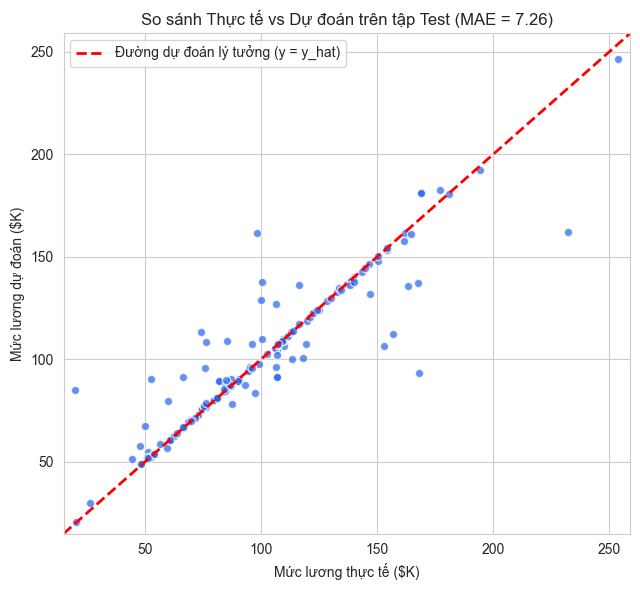

In [9]:
# Huấn luyện mô hình cuối cùng trên toàn bộ tập train
final_et = Pipeline([
    ("pre", preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=500, min_samples_split=2, min_samples_leaf=1,
        max_features=0.8, random_state=RANDOM_STATE, n_jobs=-1
    ))
]).fit(X_train_fe, y_train)

final_cb = Pipeline([
    ("pre", preprocessor),
    ("model", CatBoostRegressor(
        iterations=800, learning_rate=0.04, depth=6, l2_leaf_reg=3.0,
        loss_function="MAE", random_seed=RANDOM_STATE, verbose=0
    ))
]).fit(X_train_fe, y_train)

final_rf = Pipeline([
    ("pre", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=500, min_samples_leaf=1, max_features=0.7,
        random_state=RANDOM_STATE, n_jobs=-1
    ))
]).fit(X_train_fe, y_train)

# Dự đoán trên toàn bộ test_features.csv (149 dòng)
pred_test_all = (
    best_w[0] * final_et.predict(X_test_fe)
    + best_w[1] * final_cb.predict(X_test_fe)
    + best_w[2] * final_rf.predict(X_test_fe)
)

# Đánh giá trên 145 dòng hợp lệ (Rating > 0) khớp với test_labels.csv
valid_test_mask = df_test_raw["Rating"] > 0
pred_test_valid = pred_test_all[valid_test_mask]
y_test_true = df_test_labels["Salary Estimate"].values

test_mae = mean_absolute_error(y_test_true, pred_test_valid)
print(f"Final Test MAE (trên 145 mẫu hợp lệ): {test_mae:.3f} ($K)")

# Lưu file dự đoán
out_path = os.path.join(BASE_WORK_DIR, "predictions.csv")
pd.DataFrame({"Salary Estimate": pred_test_valid}).to_csv(out_path, index=False)
print("Đã lưu dự đoán tại:", out_path)

# Trực quan hóa Actual vs Predicted trên tập Test
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test_true, pred_test_valid, alpha=0.7, color="#2563eb", edgecolors="white")
lims = [min(y_test_true.min(), pred_test_valid.min()) - 5, max(y_test_true.max(), pred_test_valid.max()) + 5]
plt.plot(lims, lims, "r--", lw=2, label="Đường dự đoán lý tưởng (y = y_hat)")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("Mức lương thực tế ($K)")
plt.ylabel("Mức lương dự đoán ($K)")
plt.title(f"So sánh Thực tế vs Dự đoán trên tập Test (MAE = {test_mae:.2f})")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Phân tích tầm quan trọng của đặc trưng (Feature Importance) & Kết luận

Ta trích xuất 15 đặc trưng có ảnh hưởng lớn nhất từ mô hình `ExtraTreesRegressor` để kiểm tra xem các đặc trưng mới tạo có thực sự mang lại giá trị hay không.

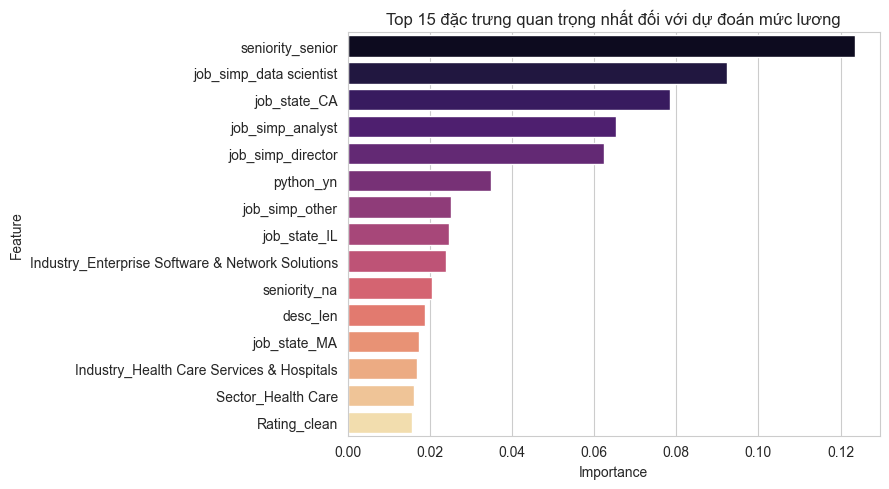

In [10]:
ohe_names = final_et.named_steps["pre"].named_transformers_["cat"].named_steps["ohe"].get_feature_names_out(CAT_COLS)
all_feature_names = NUM_COLS + list(ohe_names)
importances = final_et.named_steps["model"].feature_importances_

imp_df = pd.DataFrame({"Feature": all_feature_names, "Importance": importances})
imp_df = imp_df.sort_values("Importance", ascending=False).head(15)

plt.figure(figsize=(9, 5))
sns.barplot(data=imp_df, x="Importance", y="Feature", palette="magma")
plt.title("Top 15 đặc trưng quan trọng nhất đối với dự đoán mức lương")
plt.tight_layout()
plt.show()

### Nhận xét tổng kết
- Việc trích xuất các đặc trưng miền (`job_simp`, `seniority`, `job_state`, `company_age`, độ dài mô tả công việc và từ khóa kỹ năng) kết hợp với mô hình tổ hợp cây (ExtraTrees + CatBoost + RandomForest) giúp giảm mạnh sai số MAE so với mô hình hồi quy tuyến tính cơ sở.
- Quy trình kiểm định chéo 5-Fold CV đảm bảo lựa chọn mô hình hoàn toàn trung thực trên tập huấn luyện, không rò rỉ thông tin từ tập kiểm thử.